<div dir="rtl">

#    מבנים של מערכות תורים

### בחלק הזה נתחיל להסתכל על מערכות תורים כמבנה של תחנות וקשרים ביניהן.

### בכל תרשים, `S1`, `S2`, וכן הלאה מייצגים תחנות שירות או תורים.

### החצים מראים לאן לקוחות יכולים לעבור אחרי סיום שירות בתחנה.

### בשלב הזה המטרה היא להבין את המבנה של המערכת, לפני שנכנסים לסימולציה עצמה.

</div>

In [4]:
import matplotlib.pyplot as plt

import sys
sys.path.append('../../code')
from utils import draw_queue_network
plt.style.use('seaborn-v0_8-whitegrid')

In [1]:



def draw_queue_network(
    positions,
    edges,
    title,
    entry_nodes=None,
    exit_nodes=None,
    feedback_edges=None,
    figsize=(9, 4),
):
    entry_nodes = entry_nodes or []
    exit_nodes = exit_nodes or []
    feedback_edges = set(feedback_edges or [])

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect('equal')
    ax.axis('off')

    xs = [x for x, y in positions.values()]
    ys = [y for x, y in positions.values()]
    ax.set_xlim(min(xs) - 1.2, max(xs) + 1.2)
    ax.set_ylim(min(ys) - 0.9, max(ys) + 0.9)

    for source, target in edges:
        x1, y1 = positions[source]
        x2, y2 = positions[target]
        is_feedback = (source, target) in feedback_edges
        color = 'crimson' if is_feedback else 'black'
        linestyle = '--' if is_feedback else '-'
        rad = -0.35 if is_feedback else 0.0

        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle='-|>',
            mutation_scale=18,
            linewidth=2.0,
            color=color,
            linestyle=linestyle,
            shrinkA=24,
            shrinkB=24,
            connectionstyle=f'arc3,rad={rad}',
        )
        ax.add_patch(arrow)

    for node in entry_nodes:
        x, y = positions[node]
        arrow = FancyArrowPatch(
            (x - 0.9, y),
            (x - 0.25, y),
            arrowstyle='-|>',
            mutation_scale=18,
            linewidth=2.0,
            color='tab:blue',
        )
        ax.add_patch(arrow)
        ax.text(x - 1.05, y + 0.25, 'Arrivals', ha='center', fontsize=10, color='tab:blue')

    for node in exit_nodes:
        x, y = positions[node]
        arrow = FancyArrowPatch(
            (x + 0.25, y),
            (x + 0.9, y),
            arrowstyle='-|>',
            mutation_scale=18,
            linewidth=2.0,
            color='tab:green',
        )
        ax.add_patch(arrow)
        ax.text(x + 1.05, y + 0.25, 'Exit', ha='center', fontsize=10, color='tab:green')

    for node, (x, y) in positions.items():
        circle = Circle((x, y), 0.28, facecolor='white', edgecolor='black', linewidth=2.0, zorder=3)
        ax.add_patch(circle)
        ax.text(x, y, node, ha='center', va='center', fontsize=12, fontweight='bold', zorder=4)

    if feedback_edges:
        ax.plot([], [], color='crimson', linestyle='--', linewidth=2, label='feedback')
        ax.legend(loc='upper right')

    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.show()

<div dir="rtl">

## מערכת Tandem

### מערכת `tandem` היא מערכת שבה כל תחנה מזינה את התחנה הבאה אחריה.

### הלקוחות עוברים במסלול אחד קבוע: תחנה ראשונה, אחר כך תחנה שנייה, וכך הלאה עד היציאה.

### זה המבנה הכי פשוט של רשת תורים עם כמה תחנות.

</div>

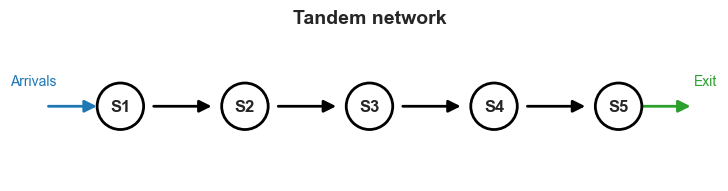

In [3]:
tandem_positions = {
    'S1': (0, 0),
    'S2': (1.5, 0),
    'S3': (3.0, 0),
    'S4': (4.5, 0),
    'S5': (6.0, 0),
}

tandem_edges = [
    ('S1', 'S2'),
    ('S2', 'S3'),
    ('S3', 'S4'),
    ('S4', 'S5'),
]

draw_queue_network(
    positions=tandem_positions,
    edges=tandem_edges,
    title='Tandem network',
    entry_nodes=['S1'],
    exit_nodes=['S5'],
)

<div dir="rtl">

## מערכות Feed-forward

### במערכת `feed-forward`, לקוחות תמיד מתקדמים קדימה ולא חוזרים לתחנות קודמות.

### עם זאת, יכולה להיות התפצלות: לקוחות שמסיימים בתחנה אחת יכולים להישלח לכמה תחנות אפשריות.

### ויכול להיות גם מיזוג: לקוחות מכמה תחנות שונות יכולים להגיע לאותה תחנה בהמשך.

### לכן המבנה כבר לא חייב להיות שרשרת אחת פשוטה.

</div>

<div dir="rtl">

## דוגמת Feed-forward עם 4 תחנות

### בדוגמה הזו יש פיצול אחרי התחנה הראשונה, ואז מיזוג לתחנה האחרונה.

### לקוחות מתחילים ב-`S1`, ממשיכים או ל-`S2` או ל-`S3`, ואז כולם מגיעים ל-`S4`.

</div>

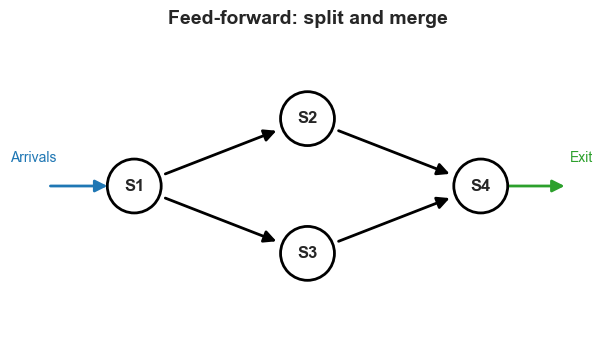

In [3]:
feed_forward_4_positions = {
    'S1': (0, 0),
    'S2': (1.8, 0.7),
    'S3': (1.8, -0.7),
    'S4': (3.6, 0),
}

feed_forward_4_edges = [
    ('S1', 'S2'),
    ('S1', 'S3'),
    ('S2', 'S4'),
    ('S3', 'S4'),
]

draw_queue_network(
    positions=feed_forward_4_positions,
    edges=feed_forward_4_edges,
    title='Feed-forward: split and merge',
    entry_nodes=['S1'],
    exit_nodes=['S4'],
)

<div dir="rtl">

## דוגמת Feed-forward עם 5 תחנות

### כאן יש שני מסלולים מקבילים אחרי התחנה הראשונה.

### המסלולים מתאחדים בתחנה האחרונה, ולכן `S5` מקבלת הגעות משתי תחנות שונות.

</div>

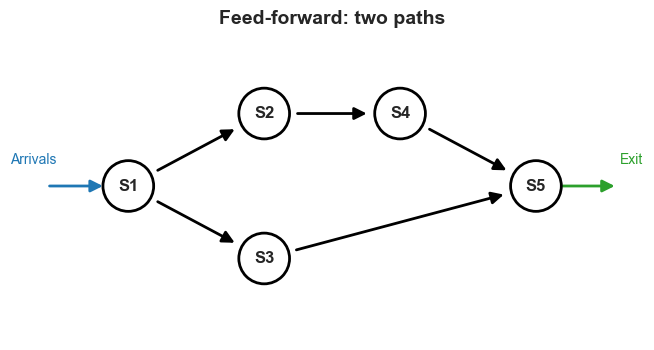

In [4]:
feed_forward_5_positions = {
    'S1': (0, 0),
    'S2': (1.5, 0.8),
    'S3': (1.5, -0.8),
    'S4': (3.0, 0.8),
    'S5': (4.5, 0),
}

feed_forward_5_edges = [
    ('S1', 'S2'),
    ('S1', 'S3'),
    ('S2', 'S4'),
    ('S3', 'S5'),
    ('S4', 'S5'),
]

draw_queue_network(
    positions=feed_forward_5_positions,
    edges=feed_forward_5_edges,
    title='Feed-forward: two paths',
    entry_nodes=['S1'],
    exit_nodes=['S5'],
)

<div dir="rtl">

## דוגמת Feed-forward עם 7 תחנות

### זו דוגמה עשירה יותר עם עד 7 תחנות.

### יש בה פיצולים ומיזוגים, אבל כל החצים עדיין הולכים קדימה בלבד.

### כלומר אין חזרה לתחנה שכבר הופיעה מוקדם יותר במסלול.

</div>

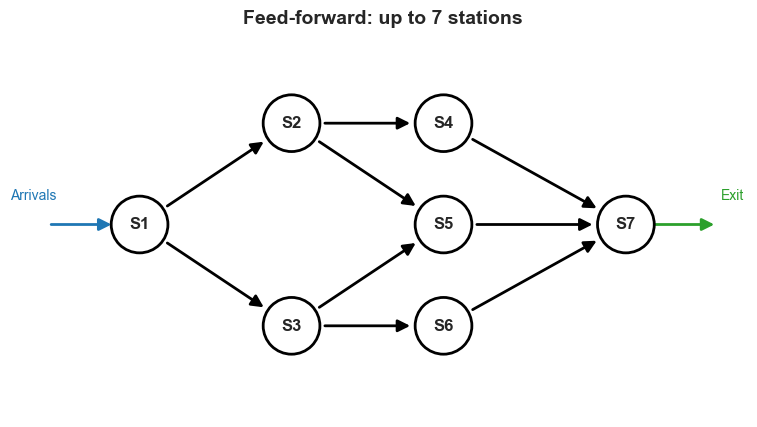

In [5]:
feed_forward_7_positions = {
    'S1': (0, 0),
    'S2': (1.5, 1.0),
    'S3': (1.5, -1.0),
    'S4': (3.0, 1.0),
    'S5': (3.0, 0.0),
    'S6': (3.0, -1.0),
    'S7': (4.8, 0.0),
}

feed_forward_7_edges = [
    ('S1', 'S2'),
    ('S1', 'S3'),
    ('S2', 'S4'),
    ('S2', 'S5'),
    ('S3', 'S5'),
    ('S3', 'S6'),
    ('S4', 'S7'),
    ('S5', 'S7'),
    ('S6', 'S7'),
]

draw_queue_network(
    positions=feed_forward_7_positions,
    edges=feed_forward_7_edges,
    title='Feed-forward: up to 7 stations',
    entry_nodes=['S1'],
    exit_nodes=['S7'],
    figsize=(10, 5),
)

<div dir="rtl">

## מערכת Feedback loop

### במערכת עם `feedback`, לקוח יכול לחזור לתחנה שכבר היה בה.

### המשמעות היא שהמסלול של הלקוח לא בהכרח מתקדם רק קדימה.

### מערכות כאלה מתאימות למשל למצבים שבהם צריך תיקון, בדיקה חוזרת, או טיפול נוסף אחרי כישלון בשלב מסוים.

</div>

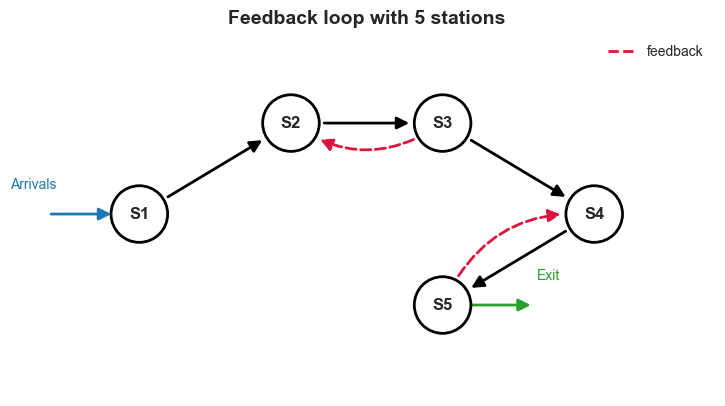

In [6]:
feedback_positions = {
    'S1': (0, 0),
    'S2': (1.5, 0.9),
    'S3': (3.0, 0.9),
    'S4': (4.5, 0.0),
    'S5': (3.0, -0.9),
}

feedback_edges = [
    ('S1', 'S2'),
    ('S2', 'S3'),
    ('S3', 'S4'),
    ('S4', 'S5'),
    ('S5', 'S4'),
    ('S3', 'S2'),
]

draw_queue_network(
    positions=feedback_positions,
    edges=feedback_edges,
    title='Feedback loop with 5 stations',
    entry_nodes=['S1'],
    exit_nodes=['S5'],
    feedback_edges=[('S5', 'S4'), ('S3', 'S2')],
    figsize=(9, 5),
)

<div dir="rtl">

## מה קורה לתהליך ההגעה בתוך רשת תורים?

### עד עכשיו, בהרבה דוגמאות בסיסיות, הנחנו שזמני הבין־הגעה הם בלתי תלויים זה בזה.

### בנוסף, בדרך כלל הנחנו שגם זמני השירות של לקוחות עוקבים הם בלתי תלויים זה בזה.

### זו הנחה סבירה בהרבה מערכות, והיא גם מקלה מאוד על הניתוח ועל הסימולציה.

### אבל ברשת תורים ההנחה הזו יכולה להישבר בצורה טבעית מאוד.

### למשל, במערכת `tandem`, תהליך העזיבה של התחנה הראשונה הוא בדיוק תהליך ההגעה לתחנה השנייה.

### כלומר גם אם ההגעות החיצוניות למערכת היו בלתי תלויות, ההגעות הפנימיות לתחנות הבאות כבר יכולות להיות תלויות.

</div>

<div dir="rtl">

## למה התפלגות כבר לא מספיקה?

### כאשר זמני הבין־הגעה בלתי תלויים, הרבה פעמים מספיק לתאר את ההתפלגות שלהם.

### לדוגמה, אפשר לומר שזמן בין הגעות מתפלג מעריכית, או גמא, או לוג־נורמלית.

### אבל אם יש תלות בין זמני בין־הגעה עוקבים, אז שתי מערכות יכולות לקבל בדיוק אותה התפלגות שולית, ועדיין להתנהג אחרת לגמרי.

### הסיבה היא שהתפלגות שולית מתארת את הערכים האפשריים של משתנה בודד, אבל לא מתארת את הסדר שבו הערכים מופיעים.

### בתורים, הסדר חשוב מאוד: רצף של הגעות צפופות יכול ליצור עומס, גם אם בממוצע קצב ההגעה נראה סביר.

</div>

<div dir="rtl">

## משתנה מקרי דו־ממדי

### עד עכשיו בדרך כלל הסתכלנו על משתנה מקרי אחד בכל פעם.

### למשל, זמן בין־הגעות אחד, זמן שירות אחד, או זמן המתנה אחד.

### אבל הרבה פעמים אנחנו רוצים לתאר שני משתנים מקריים יחד.

### זוג כזה נקרא משתנה מקרי דו־ממדי, או וקטור מקרי דו־ממדי.

### נסמן אותו כך:

### $$(X,Y)$$

### המשמעות היא שלכל תוצאה אקראית בניסוי אנחנו מקבלים שני ערכים: ערך אחד של `X` וערך אחד של `Y`.

### לדוגמה, במערכת תורים אפשר לקחת את `X` להיות זמן בין־הגעות אחד, ואת `Y` להיות זמן הבין־הגעות הבא אחריו.

</div>

<div dir="rtl">

## התפלגות משותפת

### התפלגות משותפת מתארת את ההתנהגות של שני המשתנים יחד.

### במקרה בדיד, פונקציית ההסתברות המשותפת היא:

### $$p_{X,Y}(x,y) = P(X=x, Y=y)$$

### כלומר זו ההסתברות שגם `X` יקבל את הערך `x` וגם `Y` יקבל את הערך `y`.

### במקרה רציף, משתמשים בצפיפות משותפת:

### $$f_{X,Y}(x,y)$$

### ההתפלגות המשותפת מכילה מידע לא רק על כל משתנה בנפרד, אלא גם על הקשר ביניהם.

</div>

<div dir="rtl">

## התפלגות שולית

### התפלגות שולית היא ההתפלגות של משתנה אחד בלבד, כאשר מתעלמים מהמשתנה השני.

### במקרה בדיד, אם ידועה ההתפלגות המשותפת, ההתפלגות השולית של `X` מתקבלת על ידי סכימה על כל הערכים האפשריים של `Y`:

### $$p_X(x) = \sum_y p_{X,Y}(x,y)$$

### באופן דומה, ההתפלגות השולית של `Y` היא:

### $$p_Y(y) = \sum_x p_{X,Y}(x,y)$$

### במקרה רציף מחליפים סכום באינטגרל:

### $$f_X(x) = \int_{-\infty}^{\infty} f_{X,Y}(x,y)dy$$

### ההתפלגות השולית עונה על השאלה איך משתנה אחד מתנהג בפני עצמו.

### אבל היא לא אומרת לנו האם יש קשר בינו לבין המשתנה השני.

</div>

<div dir="rtl">

## תוחלת שולית

### תוחלת שולית היא התוחלת של משתנה אחד מתוך הזוג.

### במקרה בדיד:

### $$E[X] = \sum_x x p_X(x)$$

### וגם:

### $$E[Y] = \sum_y y p_Y(y)$$

### במקרה רציף:

### $$E[X] = \int_{-\infty}^{\infty} x f_X(x)dx$$

### התוחלת השולית מתארת ממוצע של משתנה אחד בלבד.

### לכן גם אם אנחנו יודעים את `E[X]` ואת `E[Y]`, עדיין לא בהכרח יודעים האם `X` ו-`Y` תלויים זה בזה.

</div>

<div dir="rtl">

## התניה

### התניה עונה על השאלה איך משתנה אחד מתנהג כאשר ידוע לנו משהו על המשתנה השני.

### למשל, במקום לשאול מה ההתפלגות של `Y`, נשאל מה ההתפלגות של `Y` בהינתן ש-`X=x`.

### במקרה בדיד:

### $$P(Y=y \mid X=x) = \frac{P(X=x,Y=y)}{P(X=x)}$$

### או בעזרת סימון של פונקציות הסתברות:

### $$p_{Y|X}(y|x) = \frac{p_{X,Y}(x,y)}{p_X(x)}$$

### הרעיון הוא שאנחנו מצמצמים את העולם רק למקרים שבהם `X=x`, ובתוך העולם המצומצם הזה בודקים את ההתנהגות של `Y`.

### אם ההתניה על `X` משנה את ההתפלגות של `Y`, אז יש קשר בין המשתנים.

</div>

<div dir="rtl">

## תלות ואי־תלות

### שני משתנים מקריים נקראים בלתי תלויים אם הידיעה על אחד מהם לא משנה את ההתפלגות של השני.

### במקרה בדיד, תנאי שקול לאי־תלות הוא:

### $$p_{X,Y}(x,y) = p_X(x)p_Y(y)$$

### לכל `x` ו-`y`.

### במקרה כזה:

### $$P(Y=y \mid X=x) = P(Y=y)$$

### כלומר אחרי שידענו את `X`, לא למדנו שום דבר חדש על `Y`.

### לעומת זאת, אם:

### $$P(Y=y \mid X=x) \neq P(Y=y)$$

### אז ההתניה על `X` משנה את מה שאנחנו יודעים על `Y`, ולכן יש תלות.

### בהקשר של תורים, אם `X` הוא זמן בין־הגעות אחד ו-`Y` הוא זמן הבין־הגעות הבא, תלות אומרת שהמרווח הנוכחי נותן מידע על המרווח הבא.

### זו בדיוק הסיבה שבהמשך נצטרך לדבר על אוטוקורלציה.

</div>

<div dir="rtl">

## דוגמה מספרית בדידה

### הערה חשובה: אם `X` ו-`Y` הם שני זמני בין־הגעה עוקבים מאותו תהליך יציב, ההתפלגויות השוליות שלהם צריכות להיות זהות.

### לכן בדוגמה נבחר התפלגות משותפת שבה ל-`X` ול-`Y` יש אותה התפלגות שולית, אבל עדיין יש ביניהם תלות.

### נניח ש-`X` הוא זמן הבין־הגעה הנוכחי, ו-`Y` הוא זמן הבין־הגעה הבא.

### כדי לשמור על דוגמה פשוטה, נניח שכל אחד מהם יכול לקבל רק שני ערכים:

### $X=1$ או $X=2$

### $Y=1$ או $Y=2$

### אפשר לחשוב על `1` בתור זמן בין־הגעה קצר, ועל `2` בתור זמן בין־הגעה ארוך.

### נגדיר את ההתפלגות המשותפת הבאה:

### $$P(X=1,Y=1)=0.35$$

### $$P(X=1,Y=2)=0.15$$

### $$P(X=2,Y=1)=0.15$$

### $$P(X=2,Y=2)=0.35$$

### סכום כל ההסתברויות הוא `1`, ולכן זו התפלגות משותפת חוקית.

</div>

In [7]:
import pandas as pd

joint_distribution = pd.DataFrame(
    {
        'X': [1, 1, 2, 2],
        'Y': [1, 2, 1, 2],
        'P(X,Y)': [0.35, 0.15, 0.15, 0.35],
    }
)

joint_distribution

,X,Y,"P(X,Y)"
0,1,1,0.35
1,1,2,0.15
2,2,1,0.15
3,2,2,0.35


<div dir="rtl">

## חישוב התפלגות שולית

### כדי למצוא את ההתפלגות השולית של `X`, נסכום על כל הערכים האפשריים של `Y`.

### לכן:

### $$P(X=1)=P(X=1,Y=1)+P(X=1,Y=2)=0.35+0.15=0.50$$

### $$P(X=2)=P(X=2,Y=1)+P(X=2,Y=2)=0.15+0.35=0.50$$

### כדי למצוא את ההתפלגות השולית של `Y`, נסכום על כל הערכים האפשריים של `X`.

### לכן:

### $$P(Y=1)=P(X=1,Y=1)+P(X=2,Y=1)=0.35+0.15=0.50$$

### $$P(Y=2)=P(X=1,Y=2)+P(X=2,Y=2)=0.15+0.35=0.50$$

### קיבלנו בדיוק אותה התפלגות שולית עבור `X` ועבור `Y`.

### זה מתאים לפרשנות שלהם כשני זמני בין־הגעה עוקבים מאותו תהליך יציב.

</div>

In [8]:
marginal_x = (
    joint_distribution
    .groupby('X', as_index=False)['P(X,Y)']
    .sum()
    .rename(columns={'P(X,Y)': 'P(X)'})
)

marginal_y = (
    joint_distribution
    .groupby('Y', as_index=False)['P(X,Y)']
    .sum()
    .rename(columns={'P(X,Y)': 'P(Y)'})
)

display(marginal_x)
display(marginal_y)

,X,P(X)
0,1,0.5
1,2,0.5


,Y,P(Y)
0,1,0.5
1,2,0.5


<div dir="rtl">

## הצגה בטבלה דו־ממדית עם התפלגויות שוליות

### את ההתפלגות המשותפת נוח מאוד להציג כטבלה.

### הערכים בתוך הטבלה הם ההסתברויות המשותפות `P(X,Y)`.

### העמודה האחרונה היא ההתפלגות השולית של `X`.

### השורה האחרונה היא ההתפלגות השולית של `Y`.

### הפינה הימנית־תחתונה היא סכום כל ההסתברויות, ולכן היא שווה ל-`1`.

</div>

In [9]:
joint_table = joint_distribution.pivot(
    index='X',
    columns='Y',
    values='P(X,Y)',
)

joint_table.loc[:, 'P(X)'] = joint_table.sum(axis=1)
joint_table.loc['P(Y)', :] = joint_table.sum(axis=0)
joint_table.loc['P(Y)', 'P(X)'] = joint_distribution['P(X,Y)'].sum()

joint_table

Y,1,2,P(X)
X,,,
1,0.35,0.15,0.5
2,0.15,0.35,0.5
P(Y),0.50,0.50,1.0


<div dir="rtl">

## חישוב תוחלת שולית

### התוחלת השולית של `X` מחושבת מתוך ההתפלגות השולית של `X`:

### $$E[X]=1\cdot P(X=1)+2\cdot P(X=2)$$

### ולכן:

### $$E[X]=1\cdot 0.50+2\cdot 0.50=1.50$$

### התוחלת השולית של `Y` מחושבת מתוך ההתפלגות השולית של `Y`:

### $$E[Y]=1\cdot P(Y=1)+2\cdot P(Y=2)$$

### ולכן:

### $$E[Y]=1\cdot 0.50+2\cdot 0.50=1.50$$

### גם התוחלות השוליות זהות.

### ועדיין, זה לא אומר שאין תלות בין `X` לבין `Y`.

</div>

In [10]:
expected_x = (marginal_x['X'] * marginal_x['P(X)']).sum()
expected_y = (marginal_y['Y'] * marginal_y['P(Y)']).sum()

pd.DataFrame(
    {
        'quantity': ['E[X]', 'E[Y]'],
        'value': [expected_x, expected_y],
    }
)

,quantity,value
0,E[X],1.5
1,E[Y],1.5


<div dir="rtl">

## חישוב התפלגות מותנית

### עכשיו נשאל שאלה אחרת: אם ידוע לנו ש-`X=1`, מה ההתפלגות של `Y`?

### לפי נוסחת ההתניה:

### $$P(Y=y \mid X=1)=\frac{P(X=1,Y=y)}{P(X=1)}$$

### לכן:

### $$P(Y=1 \mid X=1)=\frac{0.35}{0.50}=0.70$$

### $$P(Y=2 \mid X=1)=\frac{0.15}{0.50}=0.30$$

### אם ידוע לנו ש-`X=2`, נקבל:

### $$P(Y=1 \mid X=2)=\frac{0.15}{0.50}=0.30$$

### $$P(Y=2 \mid X=2)=\frac{0.35}{0.50}=0.70$$

</div>

In [11]:
conditional_y_given_x = joint_distribution.merge(marginal_x, on='X')
conditional_y_given_x['P(Y|X)'] = (
    conditional_y_given_x['P(X,Y)'] / conditional_y_given_x['P(X)']
)

conditional_y_given_x[['X', 'Y', 'P(Y|X)']]

,X,Y,P(Y|X)
0,1,1,0.7
1,1,2,0.3
2,2,1,0.3
3,2,2,0.7


<div dir="rtl">

## מה למדנו מההתניה?

### ההתפלגות השולית של `Y` היא:

### $$P(Y=1)=0.50$$

### $$P(Y=2)=0.50$$

### אבל כאשר ידוע ש-`X=1`, ההתפלגות של `Y` משתנה:

### $$P(Y=1 \mid X=1)=0.70$$

### כלומר אם זמן הבין־הגעה הנוכחי קצר, ההסתברות שגם זמן הבין־הגעה הבא יהיה קצר עולה מ-`0.50` ל-`0.70`.

### כאשר ידוע ש-`X=2`, מקבלים:

### $$P(Y=1 \mid X=2)=0.30$$

### כלומר אם זמן הבין־הגעה הנוכחי ארוך, ההסתברות שזמן הבין־הגעה הבא יהיה קצר יורדת.

### לכן `X` ו-`Y` אינם בלתי תלויים, למרות שיש להם אותה התפלגות שולית.

### במילים של תורים: הזמן בין ההגעות הנוכחי נותן לנו מידע על הזמן בין ההגעות הבא.

### זה בדיוק הרעיון שמוביל אותנו לאוטוקורלציה.

</div>

<div dir="rtl">

## בדיקת אי־תלות בדוגמה

### אם `X` ו-`Y` היו בלתי תלויים, היינו צריכים לקבל:

### $$P(X=x,Y=y)=P(X=x)P(Y=y)$$

### למשל:

### $$P(X=1)P(Y=1)=0.50\cdot 0.50=0.25$$

### אבל בפועל:

### $$P(X=1,Y=1)=0.35$$

### מכיוון ש-$0.35 \neq 0.25$, המשתנים אינם בלתי תלויים.

### כלומר ההתפלגות המשותפת לא מתפרקת למכפלה של ההתפלגויות השוליות.

### זו דוגמה חשובה: אותה התפלגות שולית לא מבטיחה אי־תלות.

</div>

<div dir="rtl">

## אוטוקורלציה

### כדי לתאר תלות בין ערכים עוקבים באותו תהליך, משתמשים במושג שנקרא אוטוקורלציה.

### נניח שיש לנו סדרת זמנים:

### $$X_1, X_2, X_3, \ldots$$

### לדוגמה, $X_i$ יכול להיות זמן הבין־הגעה בין לקוח $i-1$ ללקוח $i$.

### אוטוקורלציה בפיגור $k$ מודדת עד כמה $X_i$ קשור ל-$X_{i+k}$.

### הנוסחה התאורטית היא:

### $$\rho_k = \frac{Cov(X_i, X_{i+k})}{Var(X_i)}$$

### כאשר התהליך סטציונרי, כלומר הממוצע והשונות לא משתנים עם הזמן.

</div>

<div dir="rtl">

## אומדן אוטוקורלציה מתוך נתונים

### אם יש לנו מדגם באורך `n`, אפשר לאמוד את האוטוקורלציה בפיגור `k` כך:

### $$\hat{\rho}_k = \frac{\sum_{i=1}^{n-k}(X_i - \bar{X})(X_{i+k} - \bar{X})}{\sum_{i=1}^{n}(X_i - \bar{X})^2}$$

### כאן $\bar{X}$ הוא ממוצע המדגם:

### $$\bar{X} = \frac{1}{n}\sum_{i=1}^{n} X_i$$

### אם $\hat{\rho}_k$ קרוב ל-`0`, אין עדות חזקה לתלות ליניארית בפיגור הזה.

### אם $\hat{\rho}_k$ חיובי, ערכים גדולים נוטים לבוא אחרי ערכים גדולים, וערכים קטנים נוטים לבוא אחרי ערכים קטנים.

### אם $\hat{\rho}_k$ שלילי, ערכים גדולים נוטים לבוא אחרי ערכים קטנים, ולהפך.

</div>

<div dir="rtl">

## אינטואיציה בתורים

### אוטוקורלציה חיובית בזמני בין־הגעה אומרת שההגעות מגיעות באשכולות.

### כלומר אם עכשיו היה זמן קצר בין שתי הגעות, יש סיכוי גבוה שגם זמן הבין־הגעה הבא יהיה קצר.

### עבור תור, זה מסוכן: אשכול של הגעות צפופות יכול ליצור עומס, להגדיל זמני המתנה, ולהשפיע על הסתברות לנטישה.

### אוטוקורלציה שלילית אומרת שיש נטייה לפיצוי: אחרי זמן בין־הגעה קצר יבוא זמן ארוך יותר.

### במקרה כזה העומס יכול להיות חלק יותר, גם אם ההתפלגות השולית של זמני הבין־הגעה זהה.

### לכן ברשתות תורים, ובמיוחד כאשר תהליך עזיבה של תחנה אחת מזין תחנה אחרת, חשוב לבדוק לא רק התפלגות אלא גם תלות בזמן.

</div>

<div dir="rtl">

## סיכום ביניים

### ראינו שלושה סוגי מבנים בסיסיים של מערכות תורים:

### 1. `tandem` - שרשרת תחנות אחת.
### 2. `feed-forward` - התקדמות קדימה עם פיצולים ומיזוגים.
### 3. `feedback` - מערכת שבה לקוחות יכולים לחזור לתחנות קודמות.

### בנוסף, ראינו נקודה חשובה: ברשת תורים, תהליך העזיבה מתחנה אחת יכול להפוך לתהליך ההגעה לתחנה הבאה.

### לכן לא תמיד מספיק לתאר את תהליך ההגעה רק בעזרת התפלגות.

### כאשר יש תלות בין זמני בין־הגעה עוקבים, צריך לדבר גם על אוטוקורלציה.

### בהמשך אפשר לקחת כל אחד מהמבנים האלה ולהוסיף לו זמני הגעה, זמני שירות, הסתברויות ניתוב, וסימולציה דינמית.

## דוגמא נומרית:

### נחשב אוטוקורלציה של תהליך עזיבה מהתור הראשון במערכת תורים של 3 תחנות שכל צרכן עובר בכולם לפי סדר תחנה 1 -> תחנה 2 -> תחנה 3 

### תחילה נעשה שגם תהליך ההגעה החיצוני הוא פואסון וגם שמני שירות מפולגים מעריכית.

### כאשר תנאים אלו מתקיימים: גם תהליך העזיבה מפולג מעריכי וערכי האוטוקורלציה הם 0 לכל k



In [1]:
import numpy as np
import simpy

In [5]:
## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time



class Queue_tandem_3:

    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates, sim_time):

        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []
        self.depart_times = {}
        
        for station in range(3):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1

        ## Defining the customers arrivals

        self.env.process(self.customer_arrivals())  ## Initializing a process

        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################

        self.sojourn_times = {}
        for station in range(3):
            self.sojourn_times[station] = []

            ##
            self.num_cust_durations.append(
                np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)

            self.depart_times[station] = []
            
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id

    ########################################################################################
    ########################################################################################

    #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6

    def customer_arrivals(self, ):

        while True:
            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)
            self.id_current += 1




            station = 0



            self.env.process(self.service(customer, station))

    #########################################################
    ################# Service block #########################
    #########################################################
    
    
    # part 7
    def service(self, customer, station):
        with self.server[station].request() as req:
            # requesting service - meanwhile waiting in line
            yield req

            # Startng service
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[station]))

            # removing the station which service took place
            #####################################################################
            # part 8

            if self.env.now > 10000:
                self.sojourn_times[station].append(self.env.now - customer.arrival_time)
                self.depart_times[station].append(self.env.now)
            ######################################################################

        
        ## Send to next station only if there are services left
        if station < 2:
        ## next station - if 2 means exit the system:
            next_station = station + 1
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))


    #########################################################################################
    # 9
    ### Running the simulation
    def run(self):
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
##########################################################################################

In [11]:
# part 1
arrival_rate = 1.5
service_rates = np.array([2, 2, 2])
sim_time = 500000

In [12]:
queue_tandem_3 = Queue_tandem_3(arrival_rate, service_rates,  sim_time)
queue_tandem_3.run()

Starting simulating two stations system...
Simulation end


In [13]:
inter_depart_0 = np.diff(queue_tandem_3.depart_times[0])

inter_depart_0

array([0.33662263, 0.05587098, 0.31174745, ..., 0.02168405, 0.2093038 ,
       1.66876502])

In [14]:
from statsmodels.tsa.stattools import acf

k = 10
autocorr = acf(inter_depart_0, nlags=k, fft=True)[1:]

print(autocorr)

[ 4.42488142e-05  3.14031866e-04 -1.07036789e-03  7.76546059e-05
  5.63558001e-04 -4.08316761e-04  9.34417019e-04 -4.24564363e-04
 -1.23098923e-03  1.01234222e-03]


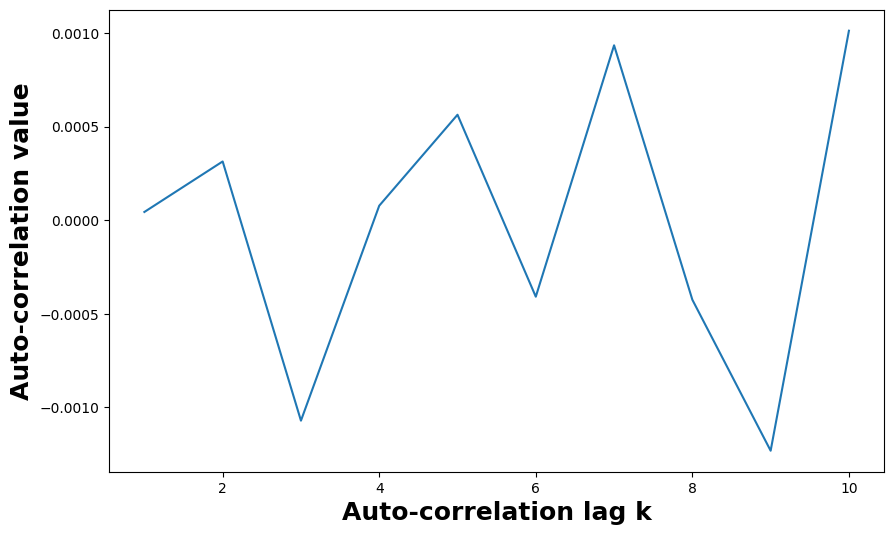

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(np.arange(1,11), autocorr)
plt.xlabel('Auto-correlation lag k', fontsize = 18, fontweight = 'bold')
plt.ylabel('Auto-correlation value', fontsize = 18, fontweight = 'bold')
plt.savefig('markovian_autocorrelation.png')
plt.show()

<div dir="rtl">

### נשנה את התפלגות השירות לgamma ולכן תהליך העזיבה כבר לא מעריכי ולמנעשה עם ערכי אוטוקרולציה שונים מ-0.

### למה הגרף מראה ערכים שהם לא בדיוק 0???

In [26]:
## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time



class Queue_tandem_3_non_markovian:

    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates, sim_time):

        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []
        self.depart_times = {}
        
        for station in range(3):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1

        ## Defining the customers arrivals

        self.env.process(self.customer_arrivals())  ## Initializing a process

        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################

        self.sojourn_times = {}
        for station in range(3):
            self.sojourn_times[station] = []

            ##
            self.num_cust_durations.append(
                np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)

            self.depart_times[station] = []
            
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id

    ########################################################################################
    ########################################################################################

    #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6

    def customer_arrivals(self, ):

        while True:
            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)
            self.id_current += 1




            station = 0



            self.env.process(self.service(customer, station))

    #########################################################
    ################# Service block #########################
    #########################################################
    
    
    # part 7
    def service(self, customer, station):
        with self.server[station].request() as req:
            # requesting service - meanwhile waiting in line
            yield req

            # Startng service

            yield self.env.timeout(np.random.gamma(1 / self.service_rates[station],1))

            # removing the station which service took place
            #####################################################################
            # part 8

            if self.env.now > 10000:
                self.sojourn_times[station].append(self.env.now - customer.arrival_time)
                self.depart_times[station].append(self.env.now)
            ######################################################################

        
        ## Send to next station only if there are services left
        if station < 2:
        ## next station - if 2 means exit the system:
            next_station = station + 1
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))


    #########################################################################################
    # 9
    ### Running the simulation
    def run(self):
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
##########################################################################################

In [27]:

queue_tandem_3_non_markovian = Queue_tandem_3_non_markovian(arrival_rate, service_rates,  sim_time)
queue_tandem_3_non_markovian.run()

Starting simulating two stations system...
Simulation end


In [28]:
inter_depart_0_non_markovian = np.diff(queue_tandem_3_non_markovian.depart_times[0])



In [29]:
k = 10
autocorr_non_markovian = acf(inter_depart_0_non_markovian, nlags=k, fft=True)[1:]

print(autocorr_non_markovian)

[-0.01068685 -0.00906594 -0.009262   -0.00898141 -0.00701024 -0.00784828
 -0.00623251 -0.00666854 -0.00695476 -0.00434007]


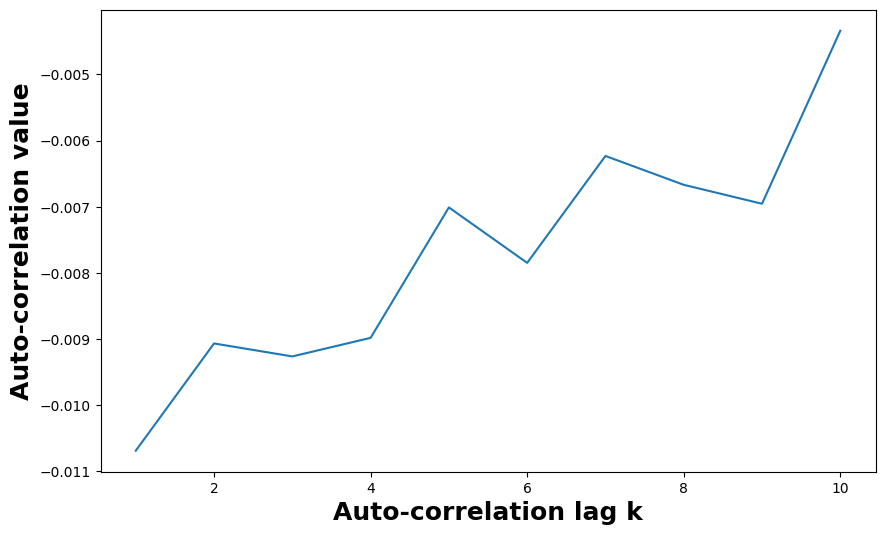

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(np.arange(1,11), autocorr_non_markovian)
plt.xlabel('Auto-correlation lag k', fontsize = 18, fontweight = 'bold')
plt.ylabel('Auto-correlation value', fontsize = 18, fontweight = 'bold')
plt.savefig('non_markovian_autocorrelation.png')
plt.show()